# Portfolio Risk Analyzer

A Python tool that pulls market data for a multi-asset portfolio and computes core risk and performance metrics: Annualised return, volatility, Sharpe ration and maximum drawdown, with supporting visualisations.

**Data:** Daily prices via 'yfinance' (Yahoo Finance) Oct 2023 - Oct 2026.

## 1. Setup

Load the libraries: 'pandas'/'numpy' for data, 'yfinance' for prices, 'matplotlib/seaborn' for charts.

In [190]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import empyrical 
from scipy.stats import norm

## 2. Data

Pull daily closing prices for six holdings.
Pull the daily closing FX rates and convert non USD denominated positions into USD.
Pull 13-week US Treasury Bill yield and assign it as the RFR.

In [ ]:
tickers = ["VTI", "QQQ", "NOK", "QTUM", "MU", "CSP1.L"]
data = yf.download(tickers, start="2023-10-01", end="2026-10-01", auto_adjust=True)
prices = data["Close"].ffill().dropna()
ticker_currencies = {ticker:yf.Ticker(ticker).history_metadata['currency'] for ticker in tickers}
base_currency = "USD"
fx_rates = {
    currency: (
        yf.download(f"{currency}{base_currency}=X",
                    start="2023-10-01", end="2026-10-01")["Close"].squeeze()
        if currency != base_currency
        else 1.0
    )
    for currency in set(ticker_currencies.values())
}
prices_base = prices.copy()

for ticker, ccy in ticker_currencies.items():
    if ccy == base_currency:                      # 'USD' -> already in base
        continue

    fx = fx_rates[ccy].reindex(prices.index).ffill().bfill()   # align to price dates
    if ccy == "GBp":                              # pence -> pounds first
        fx = fx / 100

    prices_base[ticker] = prices[ticker] * fx

prices_base = prices_base.dropna()

RFR = yf.download("^IRX", start="2023-10-01", end="2026-10-01")["Close"].squeeze() / 100

[*********************100%***********************]  6 of 6 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Ticker,CSP1.L,MU,NOK,QQQ,QTUM,VTI
Date,,,,,,
2023-10-02,36982.0,67.198334,3.457138,355.204224,46.616589,204.163559
2023-10-03,36600.0,67.069786,3.410671,348.970459,45.828281,201.199234
2023-10-04,36518.0,67.346664,3.364204,353.719574,46.100777,202.652512
2023-10-05,36378.0,68.276146,3.289857,352.677246,45.993729,202.546646
2023-10-06,36549.0,69.291313,3.308444,358.586548,46.879349,204.962387
...,...,...,...,...,...,...
2026-09-24,62602.0,1080.359985,10.430000,741.099976,152.470001,377.128235
2026-09-25,62903.0,1082.109741,10.390000,744.500000,153.720001,378.813965
2026-09-28,62504.0,1053.814087,10.120000,736.530029,151.360001,375.839996


## 3. Returns

Convert prices to daily returns with 'pct_change()', so we can have the assets on a comparable percentage scale.

Defining the weight for each asset, used to compute weighted average portfolio return. 

Assuming daily portfolio rebalancing.

In [140]:
returns = prices_base.pct_change()
returns = returns.dropna()
returns.tail()

Ticker,CSP1.L,MU,NOK,QQQ,QTUM,VTI
Date,,,,,,
2026-09-24,-0.011136,0.008070,-0.018815,-0.000148,0.000131,-0.000397
2026-09-25,0.002472,0.001620,-0.003835,0.004588,0.008198,0.004470
2026-09-28,-0.004950,-0.026149,-0.025987,-0.010705,-0.015353,-0.007851
2026-09-29,0.003659,0.010532,0.023715,0.001901,0.003369,-0.001543
2026-09-30,-0.000288,0.000028,-0.021235,0.002493,-0.001646,-0.002718


In [176]:
weights = {
    "CSP1.L": 0.10,
    "MU":     0.10,
    "NOK":    0.10,
    "QQQ":    0.25,
    "QTUM":   0.15,
    "VTI":    0.30,  
}

assert abs(sum(weights.values()) - 1) < 1e-9 # Sanity check: weights sum to 1

In [ ]:
weights_series = pd.Series(weights)

CSP1.L    0.10
MU        0.10
NOK       0.10
QQQ       0.25
QTUM      0.15
VTI       0.30
dtype: float64

In [143]:
portfolio_returns = (returns * weights_series).sum(axis=1)

# 4. Annualised Returns and Risk Metrics

Computing the annualised return, assuming 252 trading days per year.

Three risk metrics are then derived:
- **Annualised volatility** — the standard deviation of returns (scaled by √252), a measure of how much returns fluctuate: the standard proxy for risk.
- **Sharpe ratio** — return earned per unit of risk.
- **Maximum drawdown** — the largest peak-to-trough fall, i.e. the worst loss an investor would have endured.

In [ ]:
def risk_metrics_calculator(portfolio_returns, RFR, Trading_days=252):
    # Annualized returns, daily returns multiplied by the number of trading days in a year
    annualized_returns = portfolio_returns.mean() * Trading_days

    # Annualized volatility, daily returns standard deviation multiplied by the square root of the number of trading days in a year
    annualized_volatility = portfolio_returns.std() * np.sqrt(Trading_days)

    # Compounded annualized returns
    compounded_annualized_returns = empyrical.annual_return(portfolio_returns)

    # Daily excess returns, daily returns minus the risk-free rate divided by the number of trading days in a year
    excess_returns = portfolio_returns - RFR.reindex(portfolio_returns.index).ffill().bfill() / Trading_days

    # Annualized excess returns, daily excess returns multiplied by the number of trading days in a year
    annualized_excess_returns = excess_returns.mean() * Trading_days

    # Sharpe ratio, annualized excess returns divided by the annualized volatility
    sharpe_ratio = annualized_excess_returns / annualized_volatility

    # Max drawdown, the maximum drawdown of the portfolio
    cumulative = (1 + portfolio_returns).cumprod()
    running_max = cumulative.cummax()
    drawdown = (cumulative - running_max) / running_max
    max_drawdown = drawdown.min()

    # Calmar ratio, compounded annualized returns divided by the maximum drawdown
    calmar_ratio = compounded_annualized_returns / abs(max_drawdown)

    # Peak and trough dates, the dates of the maximum drawdown
    trough_date = drawdown.idxmin()
    peak_date = cumulative[:trough_date].idxmax()

    return {
        "Annualised Return": round(annualized_returns, 4),
        "compounded Annualised Return": round(compounded_annualized_returns, 4),
        "Annualised Excess Return": round(annualized_excess_returns, 4),
        "Annualised Volatility": round(annualized_volatility, 4),
        "Sharpe Ratio": round(sharpe_ratio, 4),
        "Max Drawdown": round(max_drawdown, 4),
        "Peak Date": peak_date,
        "Trough Date": trough_date,
        "Cumulative Returns": cumulative,
        "drawdown": drawdown,
        "calmar ratio": round(calmar_ratio, 4)
    }

risk_metrics = risk_metrics_calculator(portfolio_returns, RFR)
cumulative = risk_metrics['Cumulative Returns']
drawdown = risk_metrics['drawdown']

print(f"Annualised Return: {risk_metrics['Annualised Return']*100}%")
print(f"Compounded Annualised Return: {risk_metrics['compounded Annualised Return']*100}%")
print(f"Annualised Excess Return: {risk_metrics['Annualised Excess Return']*100}%")
print(f"Annualised Volatility: {risk_metrics['Annualised Volatility']*100}%")
print(f"Sharpe Ratio: {risk_metrics['Sharpe Ratio']}")
print(f"Max Drawdown: {risk_metrics['Max Drawdown']*100}%")
print(f"Calmar Ratio: {risk_metrics['calmar ratio']}")
print(f"Peak Date: {risk_metrics['Peak Date']}")
print(f"Trough Date: {risk_metrics['Trough Date']}")

Annualised Return: 36.85%
Compounded Annualised Return: 41.4%
Annualised Excess Return: 32.49%
Annualised Volatility: 20.93%
Sharpe Ratio: 1.5526
Max Drawdown: -21.3%
Calmar Ratio: 1.9436
Peak Date: 2025-02-18 00:00:00
Trough Date: 2025-04-08 00:00:00


~37% annualised return at ~21% vol — strong, but driven by a tech-heavy tilt in a favourable window.

Expected Drawdown due heavy tech holding.

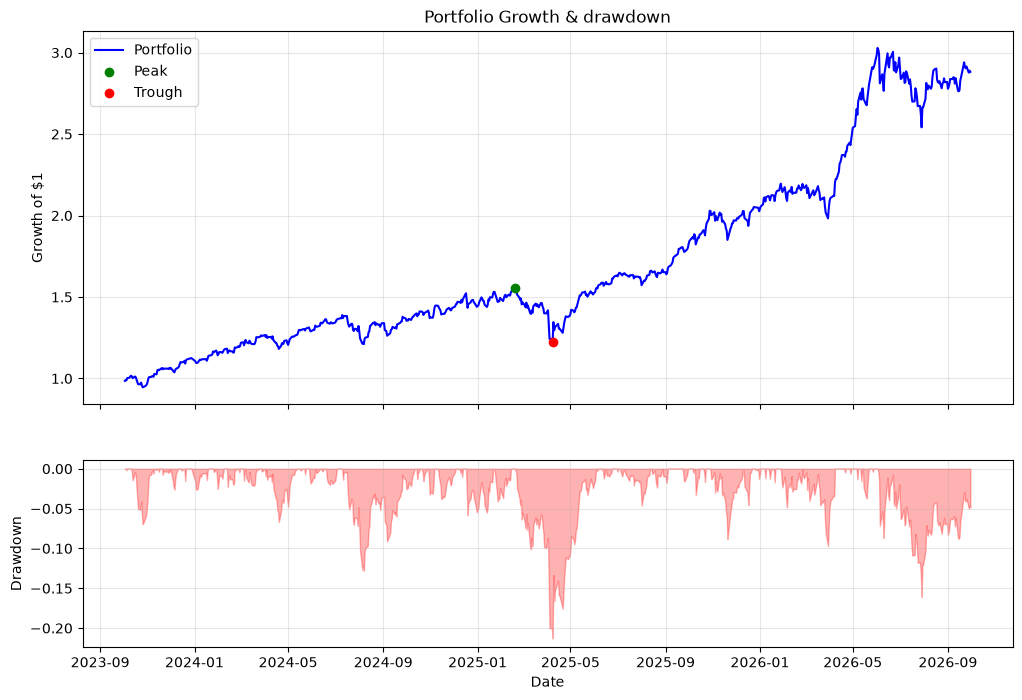

In [174]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(cumulative, label="Portfolio", color='blue')
ax1.scatter(risk_metrics['Peak Date'], cumulative[risk_metrics['Peak Date']], color='green', label='Peak', zorder=5)
ax1.scatter(risk_metrics['Trough Date'], cumulative[risk_metrics['Trough Date']], color='red', label='Trough', zorder=5)
ax1.set_title("Portfolio Growth & drawdown")
ax1.set_ylabel("Growth of $1")
ax1.legend()
ax1.grid(True, alpha=0.3)
ax2.fill_between(drawdown.index, drawdown, color='red', alpha=0.3)
ax2.set_ylabel("Drawdown")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)

In [168]:
corr = returns.corr()

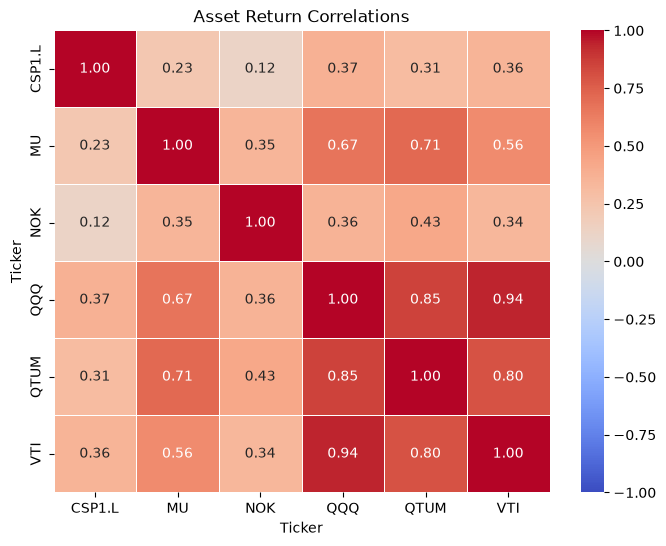

In [169]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, 
                annot=True, 
                cmap='coolwarm',
                vmin=-1, 
                vmax=1,
                center=0, 
                fmt=".2f", 
                linewidths=0.5)
plt.title("Asset Return Correlations")
plt.show()

The six holdings show relatively high correlations, driven by heavy overlap in their underlying exposure — QQQ, VTI, QTUM and MU are all tech/semiconductor-concentrated, so they effectively represent a single large US-tech bet rather than four independent positions. Genuine diversification comes from only two sources: NOK (Nokia, a Finnish telecom name uncorrelated with the tech bloc) and CSP1.L.

In [173]:
print(returns['CSP1.L'].corr(returns['VTI']))            # same-day (your ~0.36)
print(returns['CSP1.L'].corr(returns['VTI'].shift(1)))   # VTI lagged 1 day
print(returns['CSP1.L'].shift(1).corr(returns['VTI']))   # CSP1.L lagged 1 day

0.35598506429638704
0.4366476287260692
0.15810494085584031


CSP1.L’s low same-day correlation with the US names (0.36 vs VTI) is largely a non-synchronous-trading artifact: the LSE closes ~4.5h before NYSE, so US moves land in CSP1.L a day later. Lagging VTI by one day lifts the correlation to 0.44 and reveals VTI leads CSP1.L, while the reverse shift collapses to 0.16 — confirming the direction. A genuine but smaller GBP/USD overlay accounts for the residual decoupling. Naive same-day correlation therefore understates true co-movement, which would bias a risk model toward overstating diversification.

# 5. Value at Risk

- Value at Risk(VaR): The loss that won’t be exceeded on X% of days.
- Conditional(CVaR): What is the average loss if the VAR cutoff was breached.
- Parametric VaR: Assumes returns are normally distributed and computes the tail from just two numbers, the mean and the standard deviation.

In [189]:
def historical_var(portfolio_returns, cutoff=0.05):
    """
    Calculate the historical Value at Risk (VaR) of a portfolio.

    Parameters:
    portfolio_returns (pd.Series): A pandas Series of portfolio returns.
    cutoff (float): The cutoff level for VaR calculation (default is 0.05 for 95% confidence level).

    Returns:
    float: The historical VaR at the specified cutoff level.
    """
    # Calculate the quantile for the given cutoff level
    var = portfolio_returns.quantile(cutoff)
    
    return var


def conditional_var(portfolio_returns, cutoff=0.05):
    """
    Calculate the Conditional Value at Risk (CVaR) of a portfolio.

    Parameters:
    portfolio_returns (pd.Series): A pandas Series of portfolio returns.
    cutoff (float): The cutoff level for CVaR calculation (default is 0.05 for 95% confidence level).

    Returns:
    float: The conditional VaR at the specified cutoff level.
    """
    # Calculate the historical VaR
    var = historical_var(portfolio_returns, cutoff)
    
    # Calculate the conditional VaR as the mean of returns below the VaR threshold
    cvar = portfolio_returns[portfolio_returns <= var].mean()
    
    return cvar

print(f"Historical VaR (95% confidence level): {historical_var(portfolio_returns, 0.05) * 100}%")
print(f"Conditional VaR (95% confidence level): {conditional_var(portfolio_returns, 0.05) * 100}%")
print("Empyrical VaR: ", empyrical.value_at_risk(portfolio_returns, cutoff=0.05) * 100)
print("Empyrical CVaR:", empyrical.conditional_value_at_risk(portfolio_returns, cutoff=0.05) * 100)

Historical VaR (95% confidence level): -2.10868487263537%
Conditional VaR (95% confidence level): -2.89684163110854%
Empyrical VaR:  -2.10868487263537
Empyrical CVaR: -2.8968416311085385


- VaR = −2.11% at 95% confidence Level, the threshold for the worst 5% of days is −2.11%. On 95% of days we'd lose less than this. 
- CVaR = −2.90% at 95% confidence level, when we’re in that worst 5%, your average loss is −2.90%. It is the average depth of the tail.
- The Gap between VaR and CVaR ~= 0.8%, moderate to fat tail, the tail streche far past the VaR point, which fits a tech tilted portfolio that has a 21% drawdown.

In [198]:
def parametric_var(portfolio_returns, cutoff=0.05):
    """
    Calculate the Parametric Value at Risk (VaR) of a portfolio using the normal distribution assumption.

    Parameters:
    portfolio_returns (pd.Series): A pandas Series of portfolio returns.
    cutoff (float): The cutoff level for VaR calculation (default is 0.05 for 95% confidence level).

    Returns:
    float: The parametric VaR at the specified cutoff level.
    """
    # Calculate the mean and standard deviation of the portfolio returns
    mean = portfolio_returns.mean()
    std_dev = portfolio_returns.std()
    
    # Calculate the z-score for the given cutoff level
    z_score = norm.ppf(cutoff)
    
    # Calculate the parametric VaR
    p_var = mean + z_score * std_dev
    
    return p_var


def modified_var(portfolio_returns, cutoff=0.05):
    """
    Calculate the Modified Value at Risk (VaR) of a portfolio using the Cornish-Fisher expansion.

    Parameters:
    portfolio_returns (pd.Series): A pandas Series of portfolio returns.
    cutoff (float): The cutoff level for VaR calculation (default is 0.05 for 95% confidence level).

    Returns:
    float: The modified VaR at the specified cutoff level.
    """
    # Calculate the mean, standard deviation, skewness, and kurtosis of the portfolio returns
    mean = portfolio_returns.mean()
    std_dev = portfolio_returns.std()
    skewness = portfolio_returns.skew()
    kurtosis = portfolio_returns.kurtosis()
    
    # Calculate the z-score for the given cutoff level
    z_score = norm.ppf(cutoff)
    
    # Apply the Cornish-Fisher expansion to adjust the z-score for skewness and kurtosis
    modified_z_score = (z_score +
                        (1/6) * (z_score**2 - 1) * skewness +
                        (1/24) * (z_score**3 - 3*z_score) * kurtosis -
                        (1/36) * (2*z_score**3 - 5*z_score) * skewness**2)
    
    # Calculate the modified VaR
    m_var = mean + modified_z_score * std_dev
    
    return m_var

print(f"Historical VaR (95% confidence level): {historical_var(portfolio_returns, 0.05) * 100}%")
print(f"Parametric VaR (95% confidence level): {parametric_var(portfolio_returns, 0.05) * 100}%")
print(f"Modified VaR (95% confidence level): {modified_var(portfolio_returns, 0.05) * 100}%")
print(f"Historical VaR (99% confidence level): {historical_var(portfolio_returns, 0.01) * 100}%")
print(f"Parametric VaR (99% confidence level): {parametric_var(portfolio_returns, 0.01) * 100}%")
print(f"Modified VaR (99% confidence level): {modified_var(portfolio_returns, 0.01) * 100}%")

Historical VaR (95% confidence level): -2.10868487263537%
Parametric VaR (95% confidence level): -2.0222125049641546%
Modified VaR (95% confidence level): -1.839226372230144%
Historical VaR (99% confidence level): -3.138535243814916%
Parametric VaR (99% confidence level): -2.9206397661598382%
Modified VaR (99% confidence level): -4.7502968515674056%


- At both 95% and 99% confidence level, the Parametric var is less severe than the Historical VaR. This is due to the Normal distribution assumption, which underestimates our tail risk. We can also realize that the Gap widens further when we increase the confidence level.
- When we use Modified VaR, we can realize that at 95% confidence level that the value is lower than the Parametric VaR level and that can be explained by kurtosis term from the Cornish-Fisher expansion.
- The kurtosis adjustment changes sign depending on the quantile:
    - The kurtosis term in the formula: (1/24)(z³ − 3z)·K. 
    - The behaviour hinges on the sign of z³ − 3z = z(z² − 3), which flips at z = ±√3 ≈ ±1.732.
- At the 95% level, z = norm.ppf(0.05) = −1.645 — which is inside √3 (|1.645| < 1.732). Plug it in:
    - z³ − 3z = −4.45 − (−4.93) = +0.48 → positive.
    - So (1/24)(+0.48)·K with positive K is a positive addition to our z-score.
    - Adding a positive amount to −1.645 makes it less negative → less severe VaR.
- At 99% Confidence level, Modified VaR jumps to −4.75% versus parametric’s −2.92%. That’s a huge gap, and it’s the fat tails finally showing their teeth (|z| = 2.33, well past √3)


